installation et verification de yolo

In [10]:
# Installer Ultralytics pour utiliser YOLO
!pip install -q ultralytics

In [37]:
# Importer les bibliothèques nécessaires
import os
import torch
import ultralytics

from ultralytics import YOLO

# Afficher les informations de l'environnement
print("Version Ultralytics :", ultralytics.__version__)
print("Version PyTorch :", torch.__version__)

# Vérifier la disponibilité du GPU
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nom du GPU :", torch.cuda.get_device_name(0))
else:
    print("Attention : active le GPU dans Runtime > Change runtime type.")

Version Ultralytics : 8.4.204
Version PyTorch : 2.14.1+cu130
GPU disponible : True
Nom du GPU : Tesla T4


Télécharger le modèle depuis GitHub

In [12]:
# Importer les outils de téléchargement
import requests

# Créer le dossier contenant le modèle
MODEL_DIR = "/content/IotProject/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# URL du modèle publié dans GitHub Releases
MODEL_URL = (
    "https://github.com/BenWhidaAchwek/"
    "Detection_Monnaie_Tunisienne/"
    "releases/download/v0.0.1/weights.pt"
)

# Chemin de sauvegarde
MODEL_PATH = os.path.join(MODEL_DIR, "weights.pt")

# Télécharger le modèle
response = requests.get(MODEL_URL, timeout=120)
response.raise_for_status()

with open(MODEL_PATH, "wb") as file:
    file.write(response.content)

print("Téléchargement terminé.")
print("Chemin :", MODEL_PATH)
print("Taille :", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")

Téléchargement terminé.
Chemin : /content/IotProject/models/weights.pt
Taille : 18.3 MB


Charger et vérifier le modèle

In [13]:
# Charger le modèle YOLO
model = YOLO(MODEL_PATH)

# Afficher les informations du modèle
print("************************************")
print("       roboflow - YOLO MODEL")
print("************************************")

print("Modèle chargé avec succès.")
print("Nombre de classes :", len(model.names))

# Afficher les classes apprises
print("\nListe des classes :")

for class_id, class_name in model.names.items():
    print(f"ID {class_id} : {class_name}")

# Vérifier le nombre de classes attendu
if len(model.names) == 11:
    print("\nVérification réussie : 11 classes trouvées.")
else:
    print("\nAttention : le modèle ne contient pas 11 classes.")

************************************
       roboflow - YOLO MODEL
************************************
Modèle chargé avec succès.
Nombre de classes : 11

Liste des classes :
ID 0 : billet_10_dinars
ID 1 : billet_20_dinars
ID 2 : billet_50_dinars
ID 3 : billet_5_dinars
ID 4 : piece_100_millimes
ID 5 : piece_1_dinars
ID 6 : piece_200_millimes
ID 7 : piece_2_dinars
ID 8 : piece_500_millimes
ID 9 : piece_50_millimes
ID 10 : piece_5_dinars

Vérification réussie : 11 classes trouvées.


Télécharger le dataset Roboflow

In [14]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="1NkEXFRPMUstUy8Y6BSL")
project = rf.workspace("trainings-workspace-060gs").project("test-fn88j-kwbvl-tyyri")
version = project.version(1)
dataset = version.download("yolov11", location="/content/IotProject/dataset")
#Récupérer le chemin du fichier YAML
DATA_YAML = os.path.join(
    dataset.location,
    "data.yaml"
)

print("Dataset téléchargé avec succès.")
print("Fichier YAML :", DATA_YAML)
print("Fichier YAML disponible :", os.path.exists(DATA_YAML))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 87.2 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/IotProject/dataset in yolov11:: 100%|██████████| 13534/13534 [00:09<00:00, 1441.79it/s]


Dataset téléchargé avec succès.
Fichier YAML : /content/IotProject/dataset/data.yaml
Fichier YAML disponible : True


Évaluer le modèle YOLO

In [15]:
# Créer un dossier pour sauvegarder les résultats
RESULTS_DIR = "/content/IotProject/evaluation"

os.makedirs(RESULTS_DIR, exist_ok=True)

# Évaluer le modèle sur les données de validation
metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True,
    save_json=True,
    project=RESULTS_DIR,
    name="evaluation_roboflow",
    exist_ok=True
)

print("Évaluation terminée.")

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1628.3±979.7 MB/s, size: 306.8 KB)
val: Scanning /content/IotProject/dataset/valid/labels... 1347 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1347/1347 1.7Kit/s 0.8s
val: New cache created: /content/IotProject/dataset/valid/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 2210. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 169/169 5.1it/s 33.4s
                   all       1347       2210      0.901      0.841      0.912      0.769
      billet_10_dinars        282        358   

Afficher les métriques : Precision, Recall et mAP

In [19]:
# Extraire les métriques de détection
precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

# Afficher les résultats
print("======================================")
print("       roboflow model- EVALUATION")
print("======================================")

print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"mAP50       : {map50:.4f}")
print(f"mAP50-95    : {map50_95:.4f}")

       roboflow model- EVALUATION
Precision   : 0.9013
Recall      : 0.8407
mAP50       : 0.9122
mAP50-95    : 0.7691


Afficher les graphiques générés:

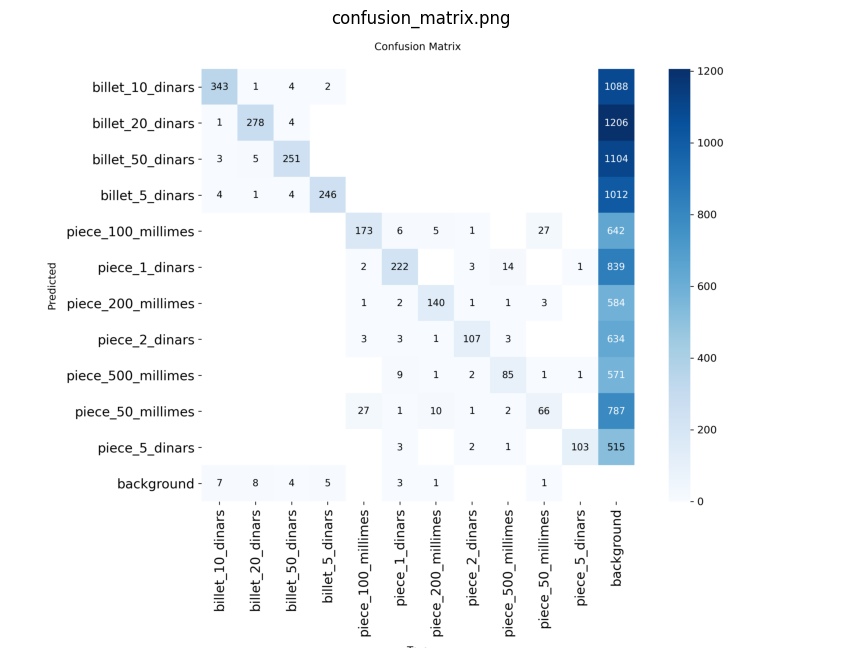

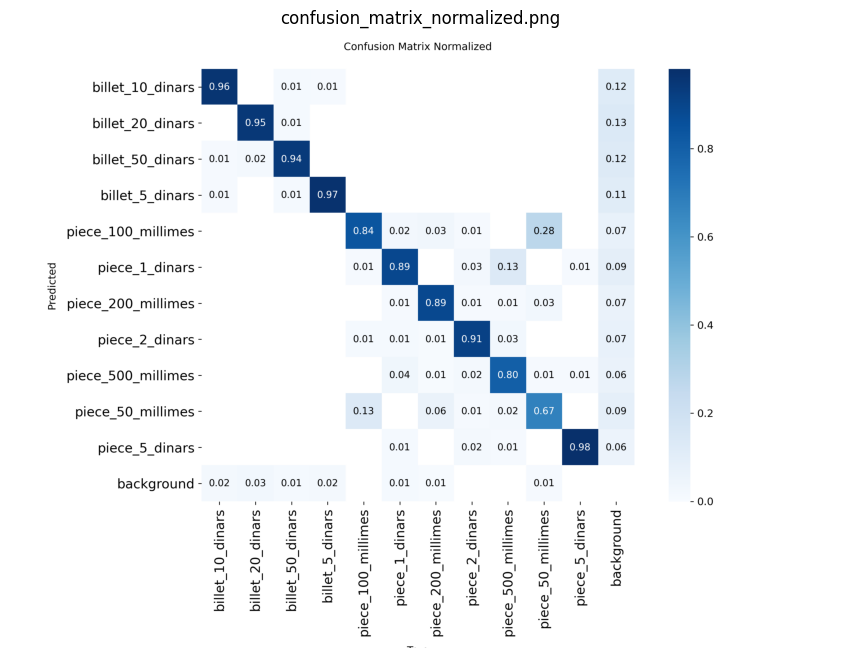

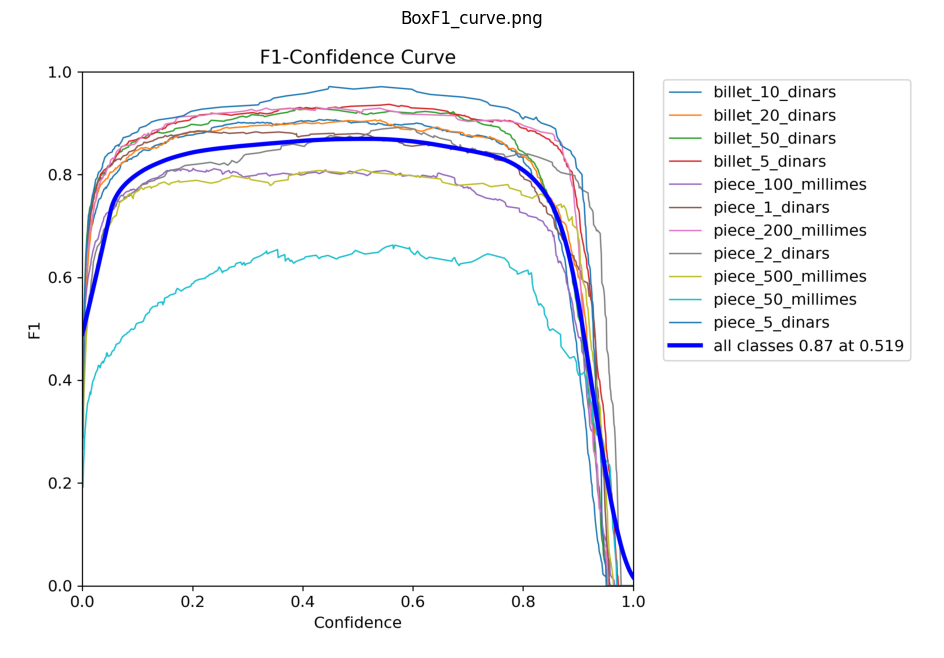

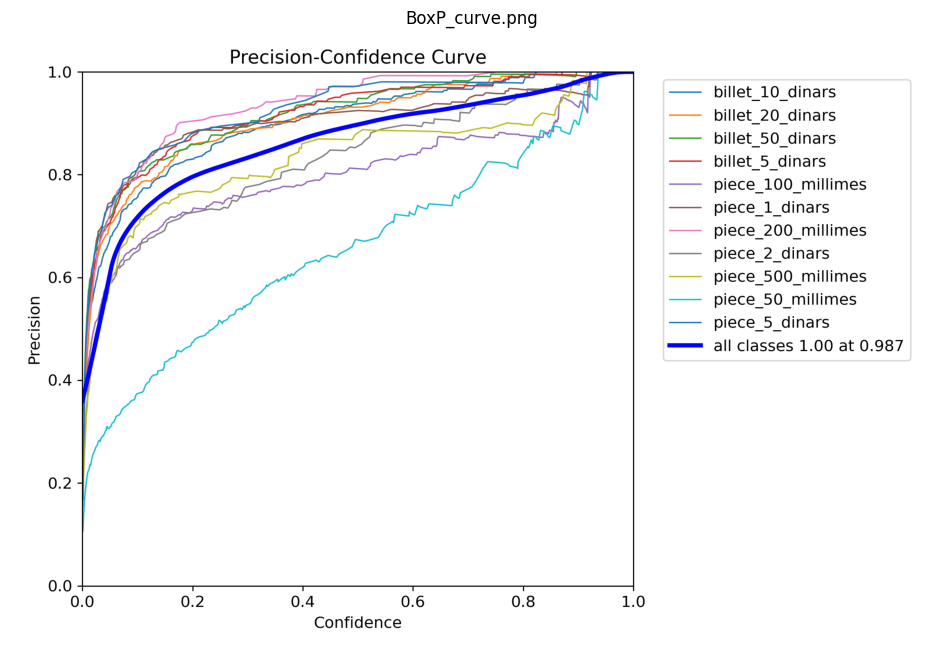

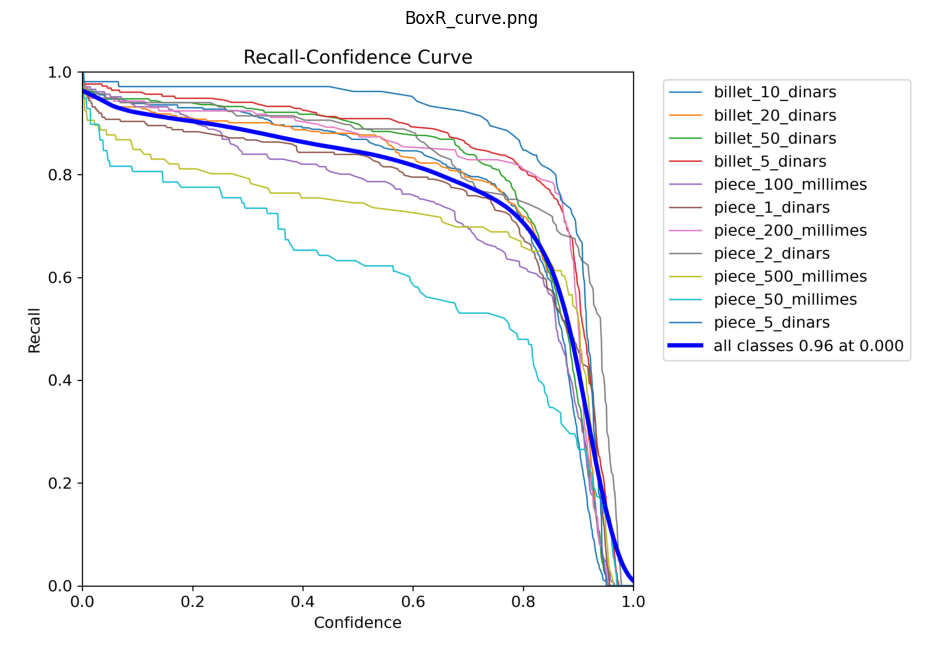

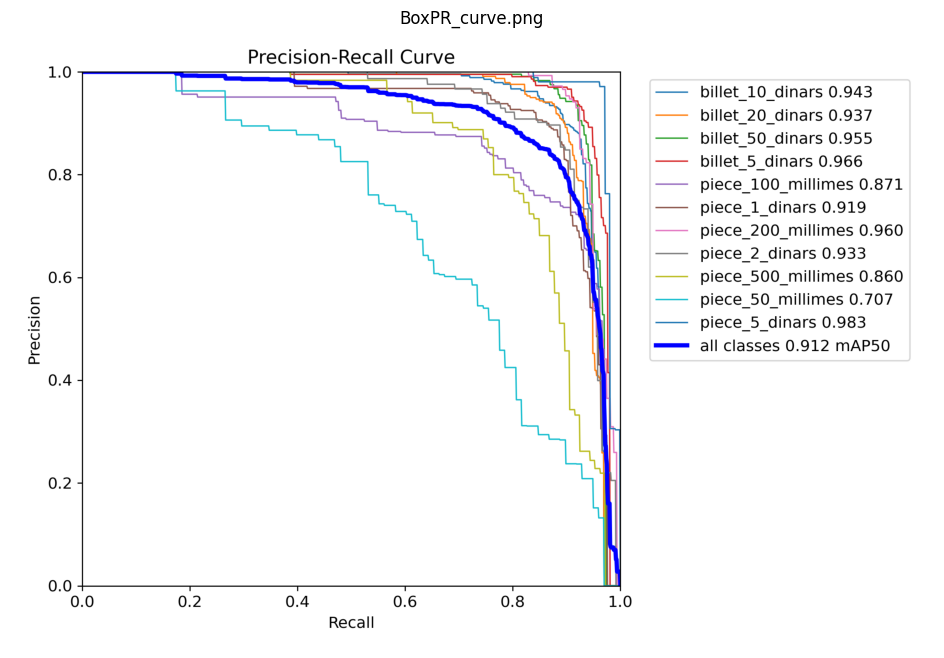

In [17]:
# Importer les outils d'affichage
import matplotlib.pyplot as plt
from PIL import Image

# Chemin du dossier contenant les graphiques
PLOT_DIR = os.path.join(
    RESULTS_DIR,
    "evaluation_roboflow"
)

# Liste des graphiques générés par YOLO
graph_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png"
]

# Afficher chaque graphique disponible
for graph_name in graph_names:

    graph_path = os.path.join(
        PLOT_DIR,
        graph_name
    )

    if os.path.exists(graph_path):

        img = Image.open(graph_path)

        plt.figure(figsize=(12, 8))
        plt.imshow(img)
        plt.title(graph_name)
        plt.axis("off")
        plt.show()

    else:
        print("Graphique non disponible :", graph_name)

Créer un graphique récapitulatif des métriques

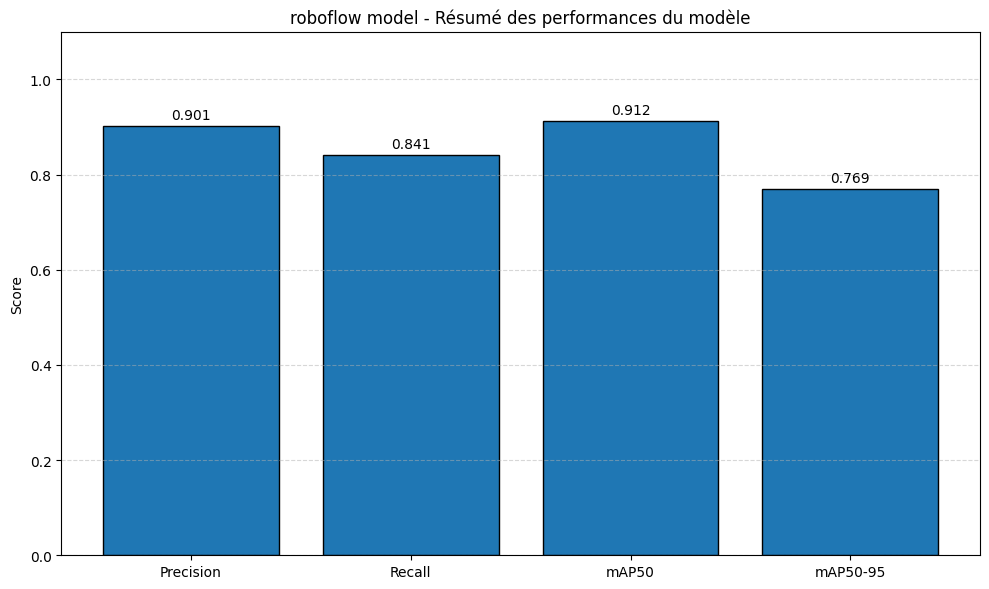

In [36]:
# Organiser les métriques dans un dictionnaire
metric_names = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

metric_values = [
    precision,
    recall,
    map50,
    map50_95
]

# Créer le graphique
plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values,
    edgecolor="black"
)

# Afficher les valeurs au-dessus des barres
for bar, value in zip(bars, metric_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.title("roboflow model - Résumé des performances du modèle")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Sauvegarder les graphiques pour le rapport

In [35]:
import pandas as pd

# Créer le dossier final du rapport
REPORT_DIR = "/content/IotProject/rapport_graphiques"

os.makedirs(REPORT_DIR, exist_ok=True)

# Copier les graphiques générés
import shutil

for graph_name in graph_names:

    source = os.path.join(PLOT_DIR, graph_name)

    if os.path.exists(source):

        destination = os.path.join(
            REPORT_DIR,
            graph_name
        )

        shutil.copy(source, destination)

# Sauvegarder le résumé des métriques
metrics_df = pd.DataFrame({
    "Metric": metric_names,
    "Value": metric_values
})

metrics_df.to_csv(
    os.path.join(REPORT_DIR, "metrics_summary.csv"),
    index=False
)

# Créer une archive ZIP
shutil.make_archive(
    "/content/roboflowModel_Graphiques_Rapport",
    "zip",
    REPORT_DIR
)

print("Graphiques sauvegardés dans :", REPORT_DIR)



Graphiques sauvegardés dans : /content/IotProject/rapport_graphiques


Test de détection sur une image

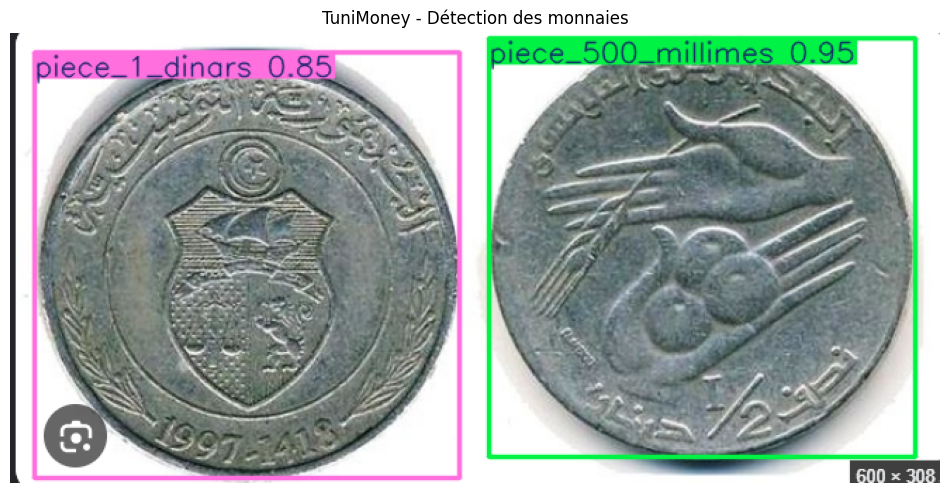

In [38]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image1.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


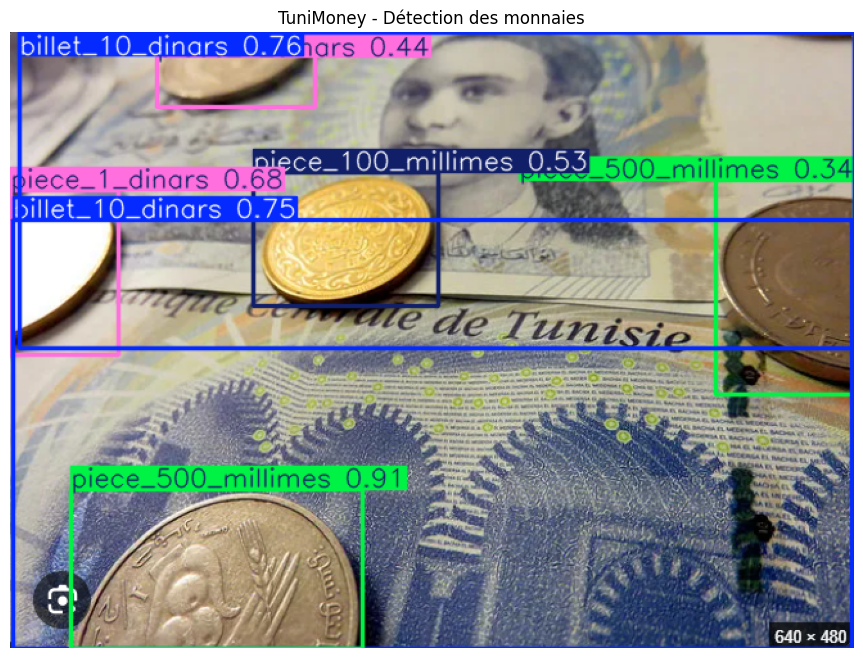

In [40]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image3.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


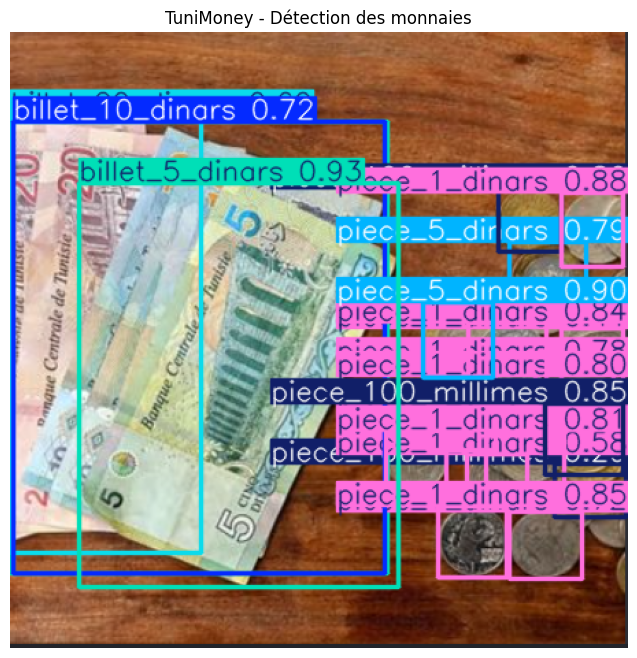


RÉSULTATS 
billet_5_dinars : 2
piece_5_dinars : 2
piece_1_dinars : 10
piece_100_millimes : 3
billet_10_dinars : 1
billet_20_dinars : 1
-----------------------------------------
Nombre total d'objets détectés : 19


In [51]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image5.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")





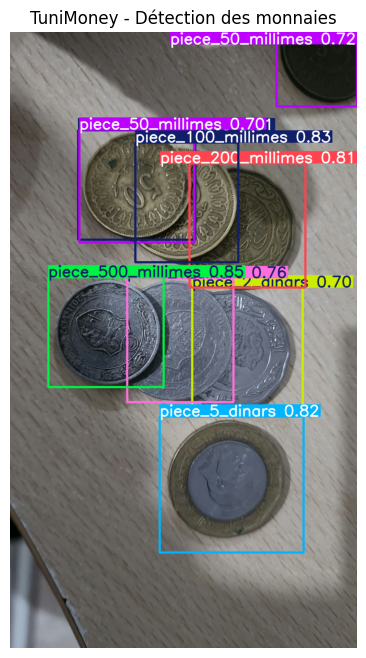


RÉSULTATS 
piece_500_millimes : 1
piece_100_millimes : 2
piece_5_dinars : 1
piece_200_millimes : 1
piece_1_dinars : 1
piece_50_millimes : 2
piece_2_dinars : 1
-----------------------------------------
Nombre total d'objets détectés : 9


In [53]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter
# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image30.jpg"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")




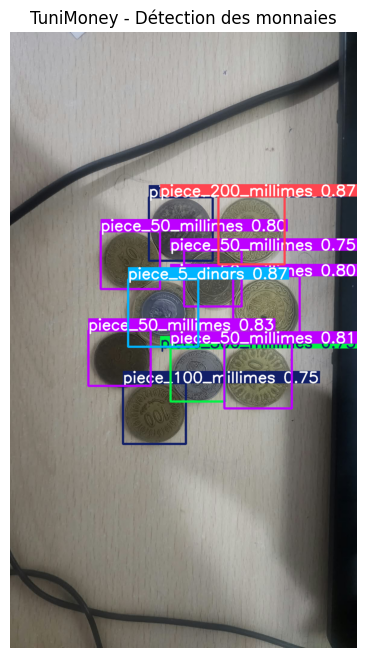


RÉSULTATS 
piece_200_millimes : 1
piece_5_dinars : 1
piece_50_millimes : 5
piece_500_millimes : 1
piece_100_millimes : 2
-----------------------------------------
Nombre total d'objets détectés : 10


In [54]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image31.jpg"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()
# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")




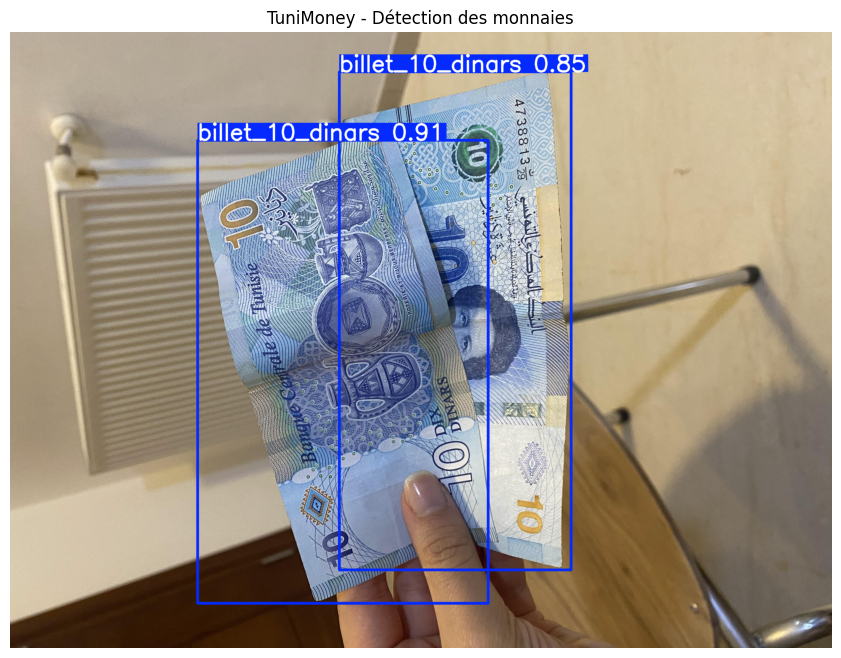


RÉSULTATS 
billet_10_dinars : 2
-----------------------------------------
Nombre total d'objets détectés : 2


In [52]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image29.JPG"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()
# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")


